In [36]:
from pathlib import Path

import numpy as np
import scipy.constants as co
import matplotlib.pyplot as plt

from bolos import parser, solver, grid

In [ ]:
# 1. 入力ファイルと計算条件
script_dir = Path.cwd()
input_file = script_dir.parent / "Phelps" / "Phelps_N2-O2_20261026.txt"

en_td_values = np.linspace(200.0, 1000.0, 9)  # Townsend換算電場 [Td]
gas_temperature_k = 300.0
fractions = {"N2": 0.6, "O2": 0.4}

if not input_file.is_file():
    raise FileNotFoundError(input_file)
if any(value < 0 for value in fractions.values()) or not np.isclose(sum(fractions.values()), 1.0):
    raise ValueError("混合比は非負とし、合計を1にしてください。")

# 2. エネルギー格子とソルバを作る
coarse_grid = grid.LinearGrid(0.0, 100.0, 1000)
bsolver = solver.BoltzmannSolver(coarse_grid)

# 3. 断面積を読み込む
with input_file.open(encoding="utf-8") as fp:
    collisions = parser.parse(fp)
bsolver.load_collisions(collisions)

# 4. 混合比・ガス温度・換算電場を設定する
for species, fraction in fractions.items():
    bsolver.set_density(species, fraction) # 混合比を設定する
bsolver.kT = gas_temperature_k * co.k / co.eV # ガス温度 [eV]

results = []
for en_td in en_td_values:
    bsolver.grid = coarse_grid  # 各電場の計算を粗い格子から始める
    bsolver.EN = en_td * solver.TOWNSEND
    bsolver.init()

    # 5. 初期分布から1回目の収束計算
    f_initial = bsolver.maxwell(2.0)
    f_coarse = bsolver.converge(f_initial, maxn=1000, rtol=1e-5)

    # 6. 平均エネルギーに合わせて格子を作り直す
    coarse_mean = bsolver.mean_energy(f_coarse)
    refined_grid = grid.QuadraticGrid(0.0, 15.0 * coarse_mean, 1000)
    bsolver.grid = refined_grid
    bsolver.init()

    # 元の格子上の分布を、新しい格子上に補間する
    f_guess = refined_grid.interpolate(f_coarse, coarse_grid)
    eedf, iterations, error = bsolver.converge(
        f_guess, maxn=1000, rtol=1e-6, full=True
)
    results.append({
        "en_td": en_td,
        "energy_eV": refined_grid.c.copy(),
        "eedf": eedf.copy(),
        "mean_energy": bsolver.mean_energy(eedf),})

    print(f"en_td={en_td:.1f} Td, mean_energy={results[-1]['mean_energy']:.3f} eV, iterations={iterations}, error={error:.2e}")

en_td=200.0 Td, mean_energy=5.543 eV, iterations=12, error=7.02e-07


en_td=300.0 Td, mean_energy=7.311 eV, iterations=7, error=6.62e-07


en_td=400.0 Td, mean_energy=8.886 eV, iterations=3, error=6.13e-07


en_td=500.0 Td, mean_energy=10.372 eV, iterations=3, error=7.36e-07


en_td=600.0 Td, mean_energy=11.804 eV, iterations=7, error=6.47e-07


en_td=700.0 Td, mean_energy=13.198 eV, iterations=7, error=4.54e-07


en_td=800.0 Td, mean_energy=14.567 eV, iterations=6, error=2.39e-07


en_td=900.0 Td, mean_energy=15.919 eV, iterations=7, error=7.53e-07


en_td=1000.0 Td, mean_energy=17.259 eV, iterations=8, error=6.67e-07


In [38]:
# 7. 結果を確認・出力する
if not np.isfinite(eedf).all() or np.min(eedf) < -1e-12:
    raise ValueError("EEDF に非有限値または負値があります。")

print(f"E/N = {en_td:g} Td, T = {gas_temperature_k:g} K")
print(f"反復回数 = {iterations}, 最終誤差 = {error:.3e}")
print(f"平均エネルギー = {bsolver.mean_energy(eedf):.8g} eV")
print(f"移動度 × N = {bsolver.mobility(eedf):.8e} 1/(m V s)")
print(f"拡散係数 × N = {bsolver.diffusion(eedf):.8e} 1/(m s)")

print("\n反応速度係数:")
for target, process in bsolver.iter_all():
    rate = bsolver.rate(eedf, process)
    print(f"{str(process):45s} {rate:.8e} m^3/s")

E/N = 1000 Td, T = 300 K
反復回数 = 8, 最終誤差 = 6.673e-07
平均エネルギー = 17.25895 eV
移動度 × N = 6.51504372e+23 1/(m V s)
拡散係数 × N = 7.91901273e+24 1/(m s)

反応速度係数:
{ELASTIC: N2 }                                1.88001302e-13 m^3/s
{ELASTIC: O2 }                                1.47428538e-13 m^3/s
{IONIZATION: N2 -> N2^+}                      1.12965211e-14 m^3/s
{IONIZATION: N2 -> N2^+(B2SIGMA)}             8.41718433e-16 m^3/s
{EXCITATION: N2 -> N2(rot)}                   7.38052728e-16 m^3/s
{EXCITATION: N2 -> N2(v1)}                    8.44595215e-16 m^3/s
{EXCITATION: N2 -> N2(v1res)}                 8.59936072e-16 m^3/s
{EXCITATION: N2 -> N2(v2)}                    5.10812589e-16 m^3/s
{EXCITATION: N2 -> N2(v3)}                    3.40694726e-16 m^3/s
{EXCITATION: N2 -> N2(v4)}                    2.35999107e-16 m^3/s
{EXCITATION: N2 -> N2(v5)}                    2.00986941e-16 m^3/s
{EXCITATION: N2 -> N2(v6)}                    1.73053794e-16 m^3/s
{EXCITATION: N2 -> N2(v7)}                  

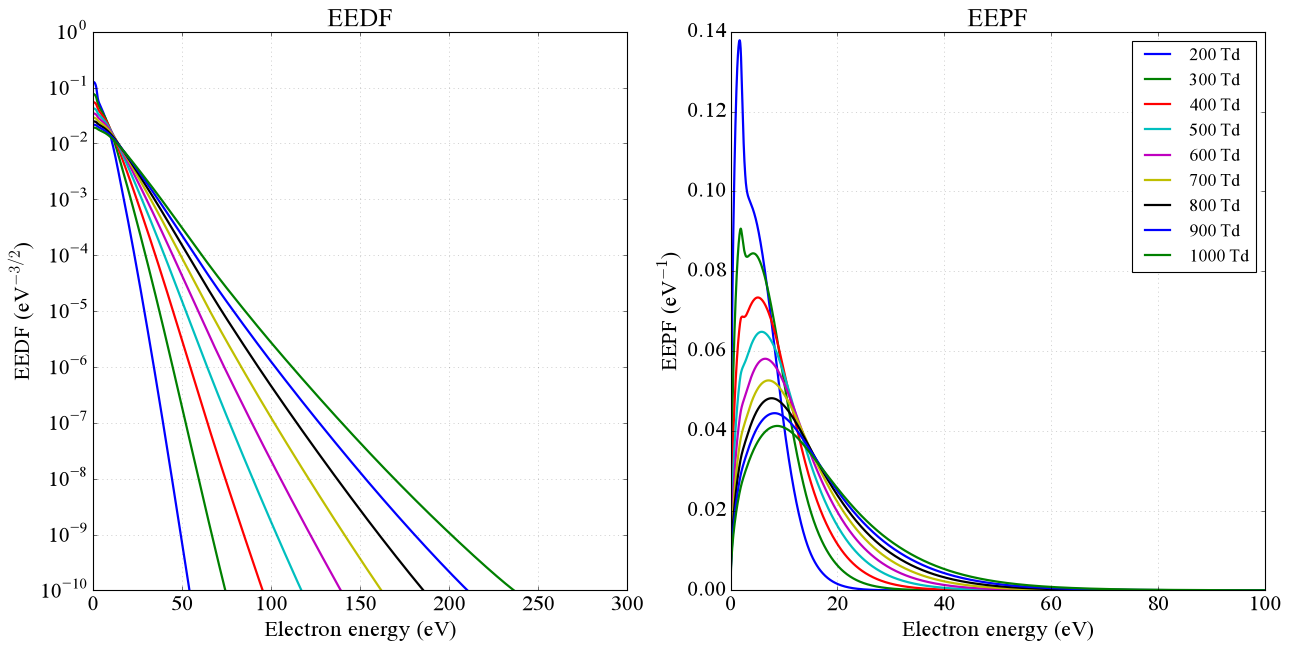

In [39]:
plt.style.use('classic')
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 20

fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True, facecolor="white")

for result in results:
    en_td = result["en_td"]
    energy_eV = result["energy_eV"]

    eedf = result["eedf"]
    eepf = np.sqrt(energy_eV) * eedf

    positive_eedf = (energy_eV > 0) & (eedf > 0)
    positive_eepf = (energy_eV > 0) & (eepf > 0)

    label = f"{en_td:g} Td"
    axes[0].plot(energy_eV[positive_eedf], eedf[positive_eedf], label=label, linewidth=2)
    axes[1].plot(energy_eV[positive_eepf], eepf[positive_eepf], label=label, linewidth=2)

for ax in axes:
    ax.set_xlabel("Electron energy (eV)")
    ax.grid(True, alpha=0.3)

axes[0].set_yscale("log")
axes[1].set_yscale("linear")

axes[0].set_ylabel("EEDF (eV$^{-3/2}$)")
axes[0].set_title("EEDF")
axes[0].set_ylim(1e-10, 1)

axes[1].set_ylabel("EEPF (eV$^{-1}$)")
axes[1].set_title("EEPF")
axes[1].legend(fontsize=16)
axes[1].set_xlim(0, 100)

plt.show()